In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time 
import seaborn as sns

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [25]:
df = pd.read_csv("uber.csv")

In [26]:
print(df.head(5))

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [27]:
print("\nDataset shape:", df.shape)



Dataset shape: (200000, 9)


In [28]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [29]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna().drop_duplicates()

In [30]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72)) &
    (df["pickup_latitude"].between(40, 42.5)) &
    (df["dropoff_latitude"].between(40, 42.5))
].copy()


In [31]:
# 3. Feature engineering
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)
df = df.dropna(subset=["pickup_datetime"])

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["weekday"] = df["pickup_datetime"].dt.weekday

In [32]:
# Calculate distance using Haversine formula
def distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )
    a = (np.sin((lat2-lat1)/2)**2 +
         np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance"] = distance(
    df["pickup_latitude"], df["pickup_longitude"],
    df["dropoff_latitude"], df["dropoff_longitude"]
)

df = df[
    (df["distance"] > 0) &
    (df["distance"] < 100) &
    (df["fare_amount"] < 100)
].copy()


In [33]:
# 4. Identify and remove outliers using IQR
for col in ["fare_amount", "distance"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df = df[
        df[col].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)
    ]

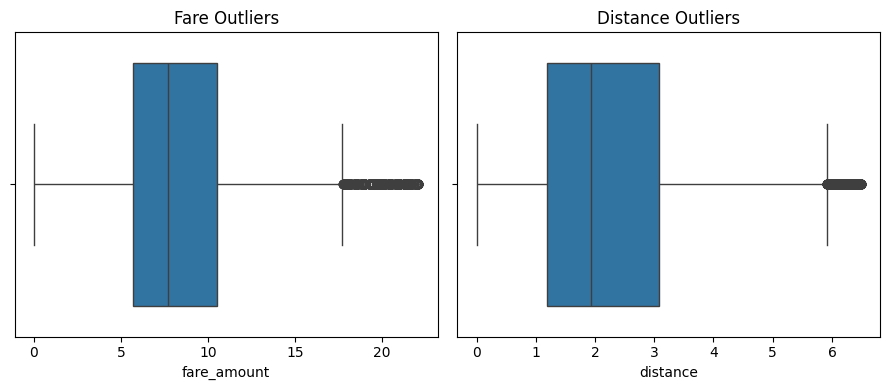

In [34]:
# Plot boxplots
plt.figure(figsize=(9, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["distance"])
plt.title("Distance Outliers")
plt.tight_layout()
plt.show()

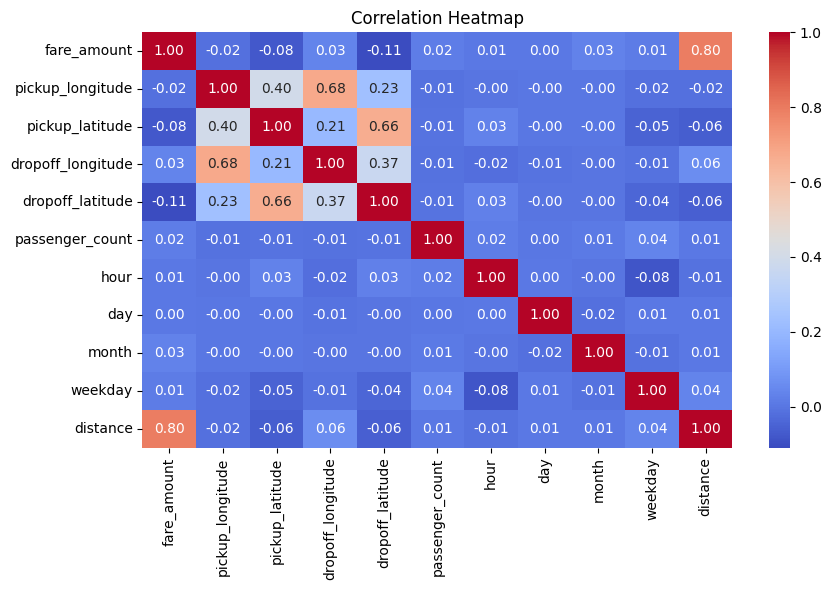

: 

In [ ]:
# 5. Correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [35]:
# 6. Select features and target
features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "distance",
    "hour", "day", "month", "weekday"
]

X = df[features]
y = df["fare_amount"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [36]:
# Scale features for Linear Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [37]:
# Train Linear Regression model
start = time.perf_counter()

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

lr_time = time.perf_counter() - start

# Evaluate Linear Regression
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_r2 = r2_score(y_test, lr_pred)

print("\n--- Linear Regression Results ---")
print("MSE:", round(lr_mse, 4))
print("RMSE:", round(lr_rmse, 4))
print("MAE:", round(lr_mae, 4))
print("R2 Score:", round(lr_r2, 4))
print("Execution Time:", round(lr_time, 4), "seconds")


--- Linear Regression Results ---
MSE: 4.9732
RMSE: 2.2301
MAE: 1.5988
R2 Score: 0.637
Execution Time: 0.0826 seconds


In [38]:
# Train Random Forest model
start = time.perf_counter()

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_time = time.perf_counter() - start

# Evaluate Random Forest
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("\n--- Random Forest Results ---")
print("MSE:", round(rf_mse, 4))
print("RMSE:", round(rf_rmse, 4))
print("MAE:", round(rf_mae, 4))
print("R2 Score:", round(rf_r2, 4))
print("Execution Time:", round(rf_time, 4), "seconds")


--- Random Forest Results ---
MSE: 4.1025
RMSE: 2.0255
MAE: 1.4335
R2 Score: 0.7006
Execution Time: 40.2111 seconds



Model Comparison:
          Linear Regression  Random Forest
R2 Score             0.6370         0.7006
RMSE                 2.2301         2.0255
MAE                  1.5988         1.4335


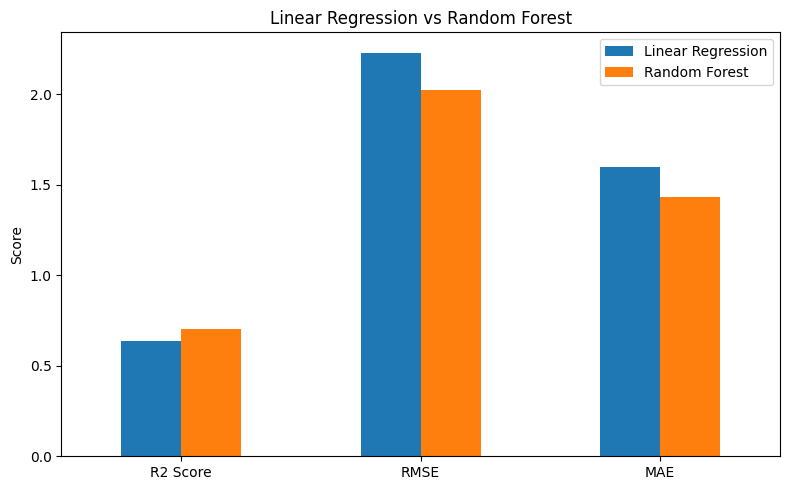

In [39]:
comparison = pd.DataFrame({
    "Linear Regression": [lr_r2, lr_rmse, lr_mae],
    "Random Forest": [rf_r2, rf_rmse, rf_mae]
}, index=["R2 Score", "RMSE", "MAE"])

print("\nModel Comparison:")
print(comparison.round(4))

comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Linear Regression vs Random Forest")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

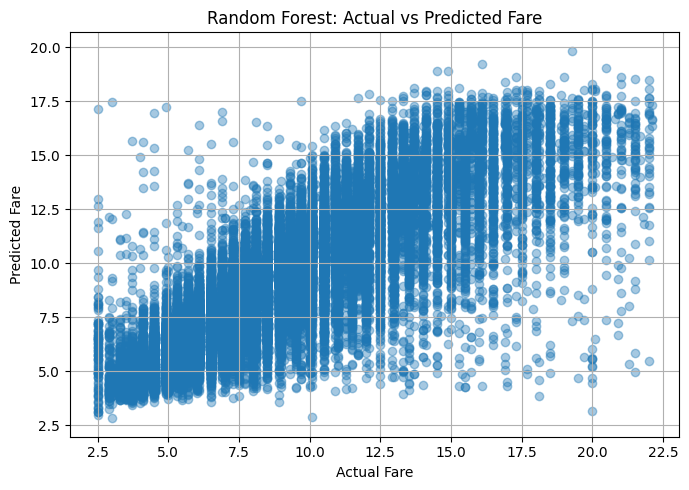

In [40]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, rf_pred, alpha=0.4)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Random Forest: Actual vs Predicted Fare")

plt.grid(True)
plt.tight_layout()
plt.show()